# Q2. Which brain area has the highest broadband LFP power (1–100 Hz) over the entire recording?

**Measure.** Each LFP channel gets a power spectrum computed over the **whole recording**, using Welch's method: 2-s Hann windows with 50% overlap, which gives 0.5 Hz resolution.
Broadband power is the area under that spectrum from 1 to 100 Hz. That equals the variance of the signal in that band, in **µV²** (the files appear to be in volts).

**Inclusion.** Every channel of every mouse is used (the dataset says the LFP was already preprocessed). Section 6 shows that no channel is an outlier that could drive the result.

**Statistics.** This is the same logic as Q1, with channels in place of units. Channels are nested in mice, so the answer uses:
- the mean over channels per area, with a hierarchical-bootstrap 95% CI (resampling mice, then channels within each mouse);
- a mixed model on log10 power, with random area effects per mouse;
- per-mouse paired tests.

**Two robustness checks.**
1. Leave out the narrow peaks that aren't brain activity: mains interference at 50 Hz and (more often) 60 Hz, plus smaller peaks at 52–53 and 66–69 Hz.
2. Average the 2-s windows with the **median** instead of the mean, so that rare large artifacts can't dominate.

The code lives in `c2p/q02_lfp_power.py` (the spectra) and `c2p/stats.py` (the area comparisons, shared with Q1).

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from c2p import AREAS, AREA_COLORS, RESULTS_DIR
from c2p import q02_lfp_power as q2
from c2p.stats import ALL_PAIRS, area_bootstrap, ci, lmm_pairwise, per_mouse_tests

ch, spectra = q2.compute()          # cached in results/; q2.compute(force=True) recomputes from the raw files (~15 min)
f = spectra["freqs"]
# robustness (a): leave out narrow non-neural peaks (mains at 50/60 Hz and a few others), from the saved spectra
ch = ch.sort_values(["mouse", "area", "channel"]).reset_index(drop=True)
ch["power_nolines_uv2"] = np.concatenate([q2.band_power(f, spectra[f"m{m}_a{a}"], exclude=q2.NARROW_PEAKS)
                                          for (m, a), _ in ch.groupby(["mouse", "area"], sort=True)])
for col in ["power_uv2", "power_nolines_uv2", "power_median_uv2"]:
    ch["log_" + col] = np.log10(ch[col])
print(f"{len(ch)} channels from {ch.mouse.nunique()} mice")
ch.pivot_table(index="area", columns="mouse", values="channel", aggfunc="size")

1862 channels from 18 mice


mouse,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
area,,,,,,,,,,,,,,,,,,
1,28,16,31,28,27,28,20,24,30,28,30,35,28,17,10,35,26,12
2,25,34,30,36,32,32,22,35,15,32,40,42,23,38,38,50,32,37
3,47,43,47,51,45,41,42,55,45,45,43,43,48,54,38,45,47,37


## 1. What the spectra look like

The left panel shows the average spectrum per area: first averaged over the channels of each mouse, then over mice (±SEM across mice). The shaded band is 1–100 Hz.
The power compared here is the area under each curve inside the band. On a log axis, the low frequencies dominate it, because the LFP spectrum falls off steeply.
The right panels show every mouse separately.

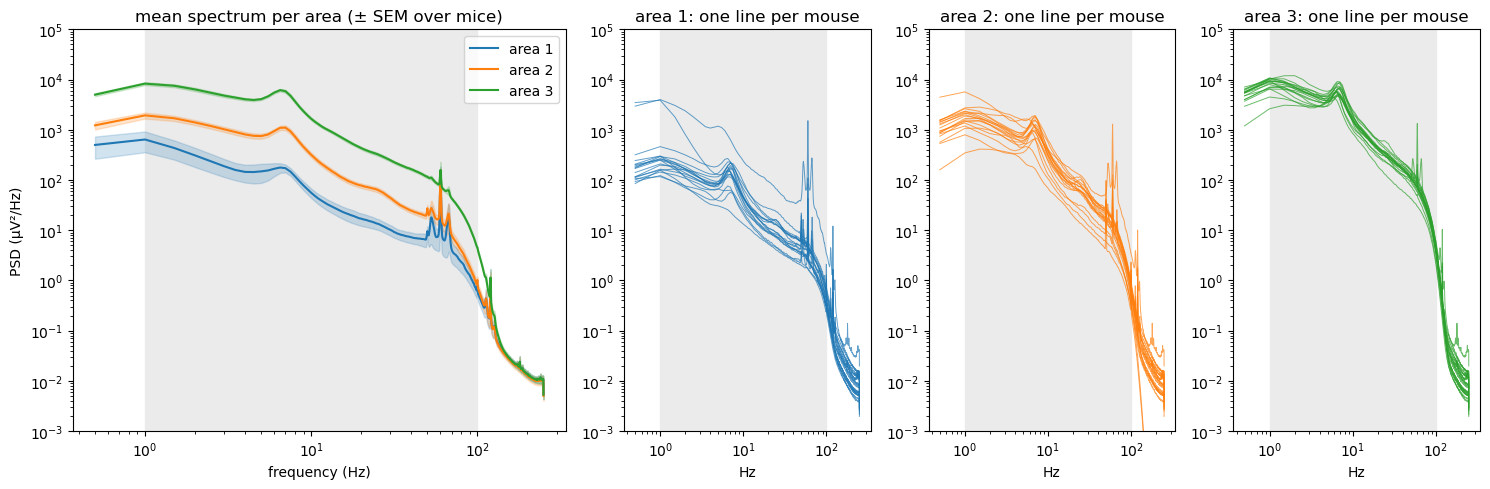

In [2]:
mice_ids = sorted(ch.mouse.unique())
mouse_spec = {a: np.array([spectra[f"m{m}_a{a}"].mean(axis=0) for m in mice_ids]) for a in AREAS}

fig = plt.figure(figsize=(15, 5))
gs = fig.add_gridspec(1, 4, width_ratios=[2, 1, 1, 1])
ax = fig.add_subplot(gs[0])
for a in AREAS:
    s = mouse_spec[a]
    m, se = s.mean(axis=0), s.std(axis=0, ddof=1) / np.sqrt(len(s))
    ax.loglog(f[1:], m[1:], color=AREA_COLORS[a], label=f"area {a}")
    ax.fill_between(f[1:], (m - se)[1:], (m + se)[1:], color=AREA_COLORS[a], alpha=0.2)
ax.axvspan(*q2.BAND, color="0.92", zorder=0)
ax.set(xlabel="frequency (Hz)", ylabel="PSD (µV²/Hz)", title="mean spectrum per area (± SEM over mice)", ylim=(1e-3, 1e5))
ax.legend()
for k, a in enumerate(AREAS):
    axk = fig.add_subplot(gs[k + 1], sharey=ax)
    axk.loglog(f[1:], mouse_spec[a][:, 1:].T, color=AREA_COLORS[a], lw=0.7, alpha=0.7)
    axk.axvspan(*q2.BAND, color="0.92", zorder=0)
    axk.set(xlabel="Hz", title=f"area {a}: one line per mouse")
fig.tight_layout()

## 2. Power along the probe

Each line is one mouse: the 1–100 Hz power of each channel, from the deepest channel (0) to the most superficial.
This shows whether power changes with depth, and whether any single channel stands out as broken.

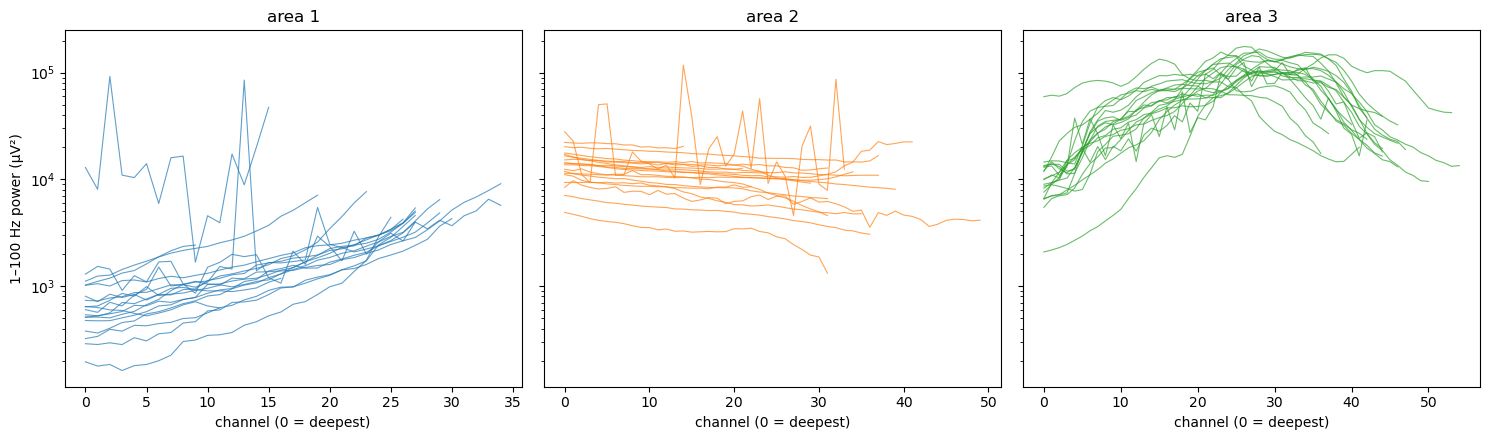

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, a in zip(axs, AREAS):
    for m, g in ch[ch.area == a].groupby("mouse"):
        ax.plot(g.channel, g.power_uv2, color=AREA_COLORS[a], lw=0.8, alpha=0.7)
    ax.set(yscale="log", xlabel="channel (0 = deepest)", title=f"area {a}")
axs[0].set_ylabel("1–100 Hz power (µV²)")
fig.tight_layout()

## 3. Mouse by mouse

Each line is one mouse's mean power per area (log axis). On the right is how often each area was the highest.

Friedman p = 0.0


,mice where x > y,n mice,wilcoxon p,wilcoxon p (Bonferroni)
pair,,,,
area 1 vs area 2,0,18,7.6e-06,0.000023
area 1 vs area 3,0,18,7.6e-06,0.000023
area 2 vs area 3,0,18,7.6e-06,0.000023


mouse,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
area,,,,,,,,,,,,,,,,,,
1,1733.0,18178.0,1210.0,1374.0,1864.0,1115.0,2848.0,1962.0,1587.0,1577.0,1668.0,2311.0,4907.0,839.0,1645.0,2444.0,765.0,613.0
2,13673.0,24679.0,13839.0,7006.0,14000.0,8132.0,13116.0,10576.0,20987.0,8776.0,11261.0,13384.0,10734.0,17094.0,12045.0,6217.0,3339.0,4948.0
3,56842.0,47500.0,82091.0,45145.0,54704.0,71554.0,63712.0,53231.0,86784.0,55033.0,80872.0,67309.0,60963.0,58893.0,59124.0,53191.0,58694.0,35936.0


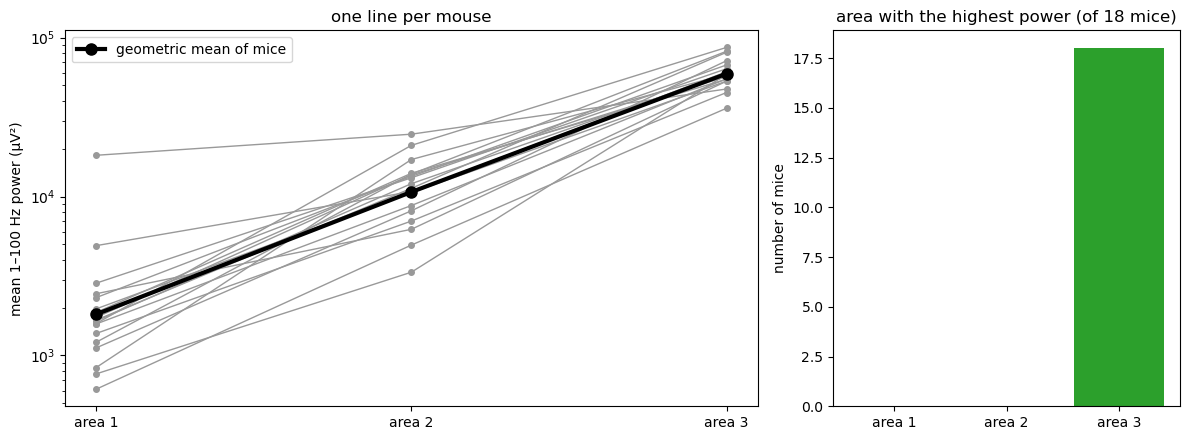

In [4]:
per_mouse, friedman, wilc = per_mouse_tests(ch, "power_uv2")
highest = per_mouse.idxmax(axis=1).value_counts().reindex(AREAS, fill_value=0)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
for m, row in per_mouse.iterrows():
    a1.plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
a1.plot(AREAS, np.exp(np.log(per_mouse).mean()).values, "-o", color="k", lw=3, ms=8, label="geometric mean of mice")
a1.set(yscale="log", xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS],
       ylabel="mean 1–100 Hz power (µV²)", title="one line per mouse")
a1.legend()
a2.bar([f"area {a}" for a in AREAS], highest.values, color=[AREA_COLORS[a] for a in AREAS])
a2.set(ylabel="number of mice", title=f"area with the highest power (of {len(per_mouse)} mice)")
fig.tight_layout()
print("Friedman p =", round(friedman.pvalue, 4))
display(wilc.style.format({"wilcoxon p": "{:.1e}"}))
per_mouse.round(0).T

## 4. Mean and 95% CI (hierarchical bootstrap)

The arithmetic mean in µV² is what the questionnaire asks for. The mean of log10 power (a geometric mean) is the robustness version: power varies by roughly 10× between mice, so a few loud mice could dominate the arithmetic mean.

In [5]:
t_lin, boot_lin = area_bootstrap(ch, "power_uv2")
t_log, boot_log = area_bootstrap(ch, "log_power_uv2")
print("Arithmetic mean (µV²):"); display(t_lin.round(1))
print("Geometric mean (µV²):"); display((10 ** t_log.iloc[:3, :3]).round(1))
print("Differences of log10 power:"); display(t_log.iloc[3:].round(4))

Arithmetic mean (µV²):


,estimate,ci_low,ci_high,p (diff = 0)
area 1,2438.4,1489.1,4068.5,NaN
area 2,11430.7,9155.9,14104.0,NaN
area 3,60615.6,54594.7,67208.5,NaN
area 1 − area 2,-8992.3,-11064.5,-6996.3,0.0
area 1 − area 3,-58177.2,-65170.0,-51600.8,0.0
area 2 − area 3,-49184.9,-55648.2,-42948.5,0.0


Geometric mean (µV²):


,estimate,ci_low,ci_high
area 1,1377.9,1073.1,1794.8
area 2,9937.4,7923.4,12288.0
area 3,45376.6,40150.4,51425.2


Differences of log10 power:


,estimate,ci_low,ci_high,p (diff = 0)
area 1 − area 2,-0.8581,-0.9623,-0.7467,0.0
area 1 − area 3,-1.5176,-1.6379,-1.3870,0.0
area 2 − area 3,-0.6596,-0.7535,-0.5614,0.0


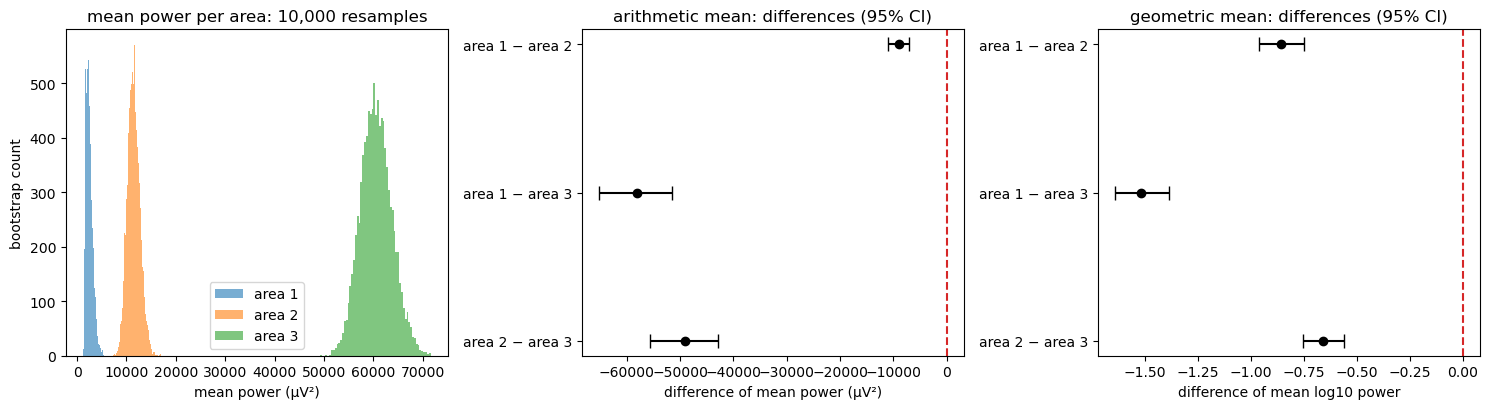

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for a in AREAS:
    k = a - 1
    axs[0].hist(boot_lin[:, k], bins=60, color=AREA_COLORS[a], alpha=0.6, label=f"area {a}")
axs[0].set(xlabel="mean power (µV²)", ylabel="bootstrap count", title="mean power per area: 10,000 resamples")
axs[0].legend()
for ax, boot, tab, lab, ttl in [(axs[1], boot_lin, t_lin, "difference of mean power (µV²)", "arithmetic mean"),
                                (axs[2], boot_log, t_log, "difference of mean log10 power", "geometric mean")]:
    for j, name in enumerate(tab.index[3:]):
        r = tab.loc[name]
        ax.errorbar(r.estimate, j, xerr=[[r.estimate - r.ci_low], [r.ci_high - r.estimate]], fmt="o", color="k", capsize=5)
    ax.axvline(0, color="tab:red", ls="--")
    ax.set(yticks=range(3), yticklabels=tab.index[3:], xlabel=lab, title=f"{ttl}: differences (95% CI)")
    ax.invert_yaxis()
fig.tight_layout()

## 5. Mixed model on log10 power

The model is `log10(power) ~ area + (area | mouse)`, as in Q1. A coefficient *c* means the first area has 10^c times the power of the second.

In [7]:
lmm = lmm_pairwise(ch, "log_power_uv2")
lmm["power ratio"] = 10 ** lmm.coef
lmm.round(4)

,coef,ci_low,ci_high,p,converged,p (Bonferroni),power ratio
contrast,,,,,,,
area 1 − area 2,-0.8664,-0.9842,-0.7486,0.0,True,0.0,0.1360
area 1 − area 3,-1.5111,-1.6520,-1.3702,0.0,True,0.0,0.0308
area 2 − area 3,-0.6447,-0.7346,-0.5547,0.0,True,0.0,0.2266


## 6. Robustness

Does the answer change if:
- (a) the narrow non-neural peaks (49–51, 52–53.5, 59–61, 66–69 Hz) are left out,
- (b) each channel's spectrum is the median rather than the mean over 2-s windows (insensitive to rare large artifacts), or
- (c) every mouse counts equally (the mean of the 18 per-mouse values, instead of pooling channels), or
- (d) outlier channels are dropped, meaning channels with more than 10× or less than 0.1× the median power of their mouse and area?

In [8]:
rel = ch.power_uv2 / ch.groupby(["mouse", "area"]).power_uv2.transform("median")
ch["outlier"] = (rel > 10) | (rel < 0.1)
print(f"outlier channels: {ch.outlier.sum()} of {len(ch)}")
display(ch[ch.outlier].assign(ratio_to_median=rel[ch.outlier])[["mouse", "area", "channel", "power_uv2", "ratio_to_median"]].round(2))

rows = {}
for col, label in [("power_uv2", "main (mean PSD, 1–100 Hz)"), ("power_nolines_uv2", "(a) without narrow peaks"),
                   ("power_median_uv2", "(b) median PSD")]:
    pm = ch.groupby(["mouse", "area"])[col].mean().unstack()
    rows[label] = {**{f"area {a}": ch[ch.area == a][col].mean() for a in AREAS},
                   "highest (pooled)": f"area {ch.groupby('area')[col].mean().idxmax()}",
                   "highest in n mice": dict(pm.idxmax(axis=1).value_counts().sort_index())}
pm = per_mouse
rows["(c) mice weighted equally"] = {**{f"area {a}": pm[a].mean() for a in AREAS},
                                     "highest (pooled)": f"area {pm.mean().idxmax()}",
                                     "highest in n mice": dict(pm.idxmax(axis=1).value_counts().sort_index())}
clean = ch[~ch.outlier]
pm_clean = clean.groupby(["mouse", "area"]).power_uv2.mean().unstack()
rows["(d) outlier channels dropped"] = {**{f"area {a}": clean[clean.area == a].power_uv2.mean() for a in AREAS},
                                        "highest (pooled)": f"area {clean.groupby('area').power_uv2.mean().idxmax()}",
                                        "highest in n mice": dict(pm_clean.idxmax(axis=1).value_counts().sort_index())}
robust = pd.DataFrame(rows).T
robust

outlier channels: 13 of 1862


,mouse,area,channel,power_uv2,ratio_to_median
1260,13,1,13,85228.99,53.72
1401,14,3,0,2088.48,0.04
1402,14,3,1,2176.92,0.04
1403,14,3,2,2292.64,0.04
1404,14,3,3,2452.85,0.04
1405,14,3,4,2683.86,0.05
1406,14,3,5,2943.23,0.05
1407,14,3,6,3297.68,0.06
1408,14,3,7,3607.51,0.06
1409,14,3,8,4080.44,0.07


,area 1,area 2,area 3,highest (pooled),highest in n mice
"main (mean PSD, 1–100 Hz)",2438.386375,11430.668987,60615.555187,area 3,{3: 18}
(a) without narrow peaks,2291.524239,11148.734051,59647.908598,area 3,{3: 18}
(b) median PSD,1633.225556,8823.885858,50516.515359,area 3,{3: 18}
(c) mice weighted equally,2702.329779,11878.12747,60643.214012,area 3,{3: 18}
(d) outlier channels dropped,2250.439812,11430.668987,61399.792782,area 3,{3: 18}


## 7. Answer for the questionnaire

In [9]:
answer = t_lin.iloc[:3, :3].copy()
answer.columns = ["Mean", "CI low", "CI high"]
answer["95% C.I."] = answer.apply(lambda r: f"[{r['CI low']:.0f}, {r['CI high']:.0f}]", axis=1)
answer["Units"] = "µV²"
answer = answer[["Mean", "95% C.I.", "Units"]].round(0)
answer.to_csv(RESULTS_DIR / "q02_answer.csv")
answer

,Mean,95% C.I.,Units
area 1,2438.0,"[1489, 4068]",µV²
area 2,11431.0,"[9156, 14104]",µV²
area 3,60616.0,"[54595, 67208]",µV²


The outliers are one broken channel in mouse 13 (area 1), one in mouse 17 (area 1), and the 11 deepest area-3 channels of mouse 14.
The mouse-14 channels are part of the steep depth gradient seen in section 2, not broken channels. None of them changes the ranking.

### Write it into the questionnaire

In [10]:
from c2p.questionnaire import fill_pdf, record_answer

m = t_lin.estimate
ratio = lambda c: 1 / lmm.loc[c, "power ratio"]
explanation = (
    f"For every LFP channel I estimated the power spectrum over the whole recording with Welch's method (2-s Hann "
    f"windows, 50% overlap) and integrated it between 1 and 100 Hz, which gives the variance of the signal in that band "
    f"in µV². All {len(ch)} channels from the {ch.mouse.nunique()} mice were used. Because channels recorded in the same "
    f"mouse are not independent, the mean of each area is reported with a hierarchical bootstrap CI, in which mice and "
    f"then channels within each mouse were resampled 10,000 times. Area 3 has by far the highest power, about "
    f"{m['area 3'] / m['area 2']:.0f} times that of area 2 and {m['area 3'] / m['area 1']:.0f} times that of area 1, "
    f"and it is the highest in every one of the {len(per_mouse)} mice (Wilcoxon p < 0.001 against each other area). "
    f"A linear mixed model on log10 power with random area effects per mouse gives the same result (area 3 / area 2 = "
    f"{ratio('area 2 − area 3'):.1f}x, area 3 / area 1 = {ratio('area 1 − area 3'):.0f}x, both p < 0.001). The "
    f"ranking does not change when the narrow mains-noise peaks at 50 and 60 Hz (and smaller ones at 52–53 and 66–69 Hz) are removed, when the spectrum is averaged with the median "
    f"to discount artifacts, when the {ch.outlier.sum()} outlier channels are excluded, or when every mouse is weighted "
    f"equally."
)
explanation += " Pairwise p-values are Bonferroni-corrected for the three comparisons."
print(len(explanation.split()), "words")
record_answer(2, choice=2,                                   # 0 = area 1, 1 = area 2, 2 = area 3, 3 = not enough data
              rows=[(f"{r.Mean:.0f}", r["95% C.I."], r.Units) for _, r in answer.iterrows()],
              explanation=explanation)
print(fill_pdf())
print(explanation)

220 words


/home/dariosannino/con2phys/docs/questionnaire_filled.pdf
For every LFP channel I estimated the power spectrum over the whole recording with Welch's method (2-s Hann windows, 50% overlap) and integrated it between 1 and 100 Hz, which gives the variance of the signal in that band in µV². All 1862 channels from the 18 mice were used. Because channels recorded in the same mouse are not independent, the mean of each area is reported with a hierarchical bootstrap CI, in which mice and then channels within each mouse were resampled 10,000 times. Area 3 has by far the highest power, about 5 times that of area 2 and 25 times that of area 1, and it is the highest in every one of the 18 mice (Wilcoxon p < 0.001 against each other area). A linear mixed model on log10 power with random area effects per mouse gives the same result (area 3 / area 2 = 4.4x, area 3 / area 1 = 32x, both p < 0.001). The ranking does not change when the narrow mains-noise peaks at 50 and 60 Hz (and smaller ones at 52–53 

## Conclusion

**Area 3 has the highest broadband LFP power.** It's about 5× area 2 and 25× area 1, it's the highest in all 18 mice, and the ranking holds under every robustness check.
Unlike Q1, this one is not close.